# HealthyAir - Data Cleaning Notebook
This notebook prepares the UCI Air Quality dataset for downstream analysis and forecasting.

The raw dataset is loaded, inspected and cleaned by correcting data types, validating timestamps, removing empty columns and identifying invalid sensor measurements. Missing values are retained for subsequent preprocessing.

The cleaned dataset is saved for use by the chronological splitting and modelling pipeline.

In [1]:
# Import Libraries
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")

print(PROJECT_ROOT)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)

/home/chloekc/datahandling/healthyair
NumPy: 2.5.3
pandas: 3.0.6
Matplotlib: 3.11.1
Seaborn: 0.13.2


## 1. Load and validate data

In [2]:
# Healthy Air Project GCS Configuration
# ---------------------------------------------------------------------
GCS_PROJECT_ID = "healthy_air_analysis"
GCS_BUCKET = "uci_air_quality_20119102"
GCS_FILE = "gs://uci_air_quality_20119102/data_raw/AirQualityUCI.csv"
df = pd.read_csv(GCS_FILE)

# Data contract
required = {"Date", "Time", "CO(GT)", "PT08.S1(CO)", "NMHC(GT)", "C6H6(GT)",
            "PT08.S2(NMHC)", "NOx(GT)", "PT08.S3(NOx)", "NO2(GT)", "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"}
assert required.issubset(df.columns)
print("Initial data-contract checks passed.")

print("Dataset:", GCS_BUCKET)
print(f"Rows: {df.shape[0]:,}; columns: {df.shape[1]}")
display(df.head())

Initial data-contract checks passed.
Dataset: uci_air_quality_20119102
Rows: 9,471; columns: 17


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,3/10/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,3/10/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,3/10/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,3/10/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,3/10/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


## 2. Timestamp Analysis

In [3]:
# Preserve original dataset
df_clean = df.copy()

# Combine Date and Time using format "%m/%d/%Y %H:%M:%S" with pd.to_datetime
df_clean["Datetime"] = pd.to_datetime(
    df_clean["Date"].astype("string").str.strip() + " " +
    df_clean["Time"].astype("string").str.strip(),
    format="%m/%d/%Y %H:%M:%S",
    errors="coerce"
)

# Validate timestamps
print("Total rows:", len(df_clean))
print("Valid timestamps:", df_clean["Datetime"].notna().sum())
print("Missing timestamps:", df_clean["Datetime"].isna().sum())

print("\nFirst timestamp:", df_clean["Datetime"].min())
print("Last timestamp:", df_clean["Datetime"].max())

Total rows: 9471
Valid timestamps: 9357
Missing timestamps: 114

First timestamp: 2004-03-10 18:00:00
Last timestamp: 2005-04-04 14:00:00


In [4]:
# Non empty rows with missing timestamp values
missing_dates = df_clean[df_clean["Datetime"].isna()]
print("Rows with missing timestamps:", len(missing_dates))

Rows with missing timestamps: 114


In [5]:
# Remove rows without a valid timestamp as rows have no data and sort chronologically
df_clean = (
    df_clean
    .dropna(subset=["Datetime"])
    .sort_values("Datetime")
    .reset_index(drop=True)
)

print("Cleaned dataset shape:", df_clean.shape)
print("First observation:", df_clean["Datetime"].min())
print("Last observation:", df_clean["Datetime"].max())

# Interval Analysis
time_diff = df_clean["Datetime"].diff()

print("Time interval counts:")
print(time_diff.value_counts().head(10))

print("\nIntervals exactly one hour:", 
      (time_diff == pd.Timedelta(hours=1)).sum())

print("Intervals shorter than one hour:",
      (time_diff < pd.Timedelta(hours=1)).sum())

print("Intervals longer than one hour:",
      (time_diff > pd.Timedelta(hours=1)).sum())

Cleaned dataset shape: (9357, 18)
First observation: 2004-03-10 18:00:00
Last observation: 2005-04-04 14:00:00
Time interval counts:
Datetime
0 days 01:00:00    9356
Name: count, dtype: int64

Intervals exactly one hour: 9356
Intervals shorter than one hour: 0
Intervals longer than one hour: 0


Timestamp Analysis Result: It appears that every observation is exactly one hour apart and target for next hour prediction could be viable with this dataset. Further checks in storage notebook, data_storage_gcs.ipynb.

## 3. Check duplicates, gaps and ranges

In [6]:
print("Duplicate timestamps:", df_clean["Datetime"].duplicated().sum())

Duplicate timestamps: 0


In [7]:
print("Date range:")
print(df_clean["Datetime"].min(), "to", df_clean["Datetime"].max())
display(df_clean[["Datetime", "Date", "Time"]].head(10))
display(df_clean[["Datetime", "Date", "Time"]].tail(5))

Date range:
2004-03-10 18:00:00 to 2005-04-04 14:00:00


,Datetime,Date,Time
0,2004-03-10 18:00:00,3/10/2004,18:00:00
1,2004-03-10 19:00:00,3/10/2004,19:00:00
2,2004-03-10 20:00:00,3/10/2004,20:00:00
3,2004-03-10 21:00:00,3/10/2004,21:00:00
4,2004-03-10 22:00:00,3/10/2004,22:00:00
5,2004-03-10 23:00:00,3/10/2004,23:00:00
6,2004-03-11 00:00:00,3/11/2004,0:00:00
7,2004-03-11 01:00:00,3/11/2004,1:00:00
8,2004-03-11 02:00:00,3/11/2004,2:00:00
9,2004-03-11 03:00:00,3/11/2004,3:00:00


,Datetime,Date,Time
9352,2005-04-04 10:00:00,4/4/2005,10:00:00
9353,2005-04-04 11:00:00,4/4/2005,11:00:00
9354,2005-04-04 12:00:00,4/4/2005,12:00:00
9355,2005-04-04 13:00:00,4/4/2005,13:00:00
9356,2005-04-04 14:00:00,4/4/2005,14:00:00


In [8]:
empty_cols = df_clean.columns[
    df_clean.isna().all()
]

df_clean = df_clean.drop(columns=empty_cols)

print("Removed empty columns:", list(empty_cols))

Removed empty columns: ['Unnamed: 15', 'Unnamed: 16']


## 4. Missing-value strategy

This template retains missing measurements rather than imputing across the full time series.

In [9]:
# Replace invalid sensor readings with missing values
df_clean = df_clean.replace(
    -200,
    np.nan
)

In [10]:
missing_pct = (
    df_clean.isnull()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

print(missing_pct)

NMHC(GT)         90.231912
CO(GT)           17.986534
NO2(GT)          17.548360
NOx(GT)          17.516298
C6H6(GT)          3.911510
PT08.S2(NMHC)     3.911510
PT08.S3(NOx)      3.911510
PT08.S1(CO)       3.911510
T                 3.911510
RH                3.911510
PT08.S4(NO2)      3.911510
PT08.S5(O3)       3.911510
AH                3.911510
Date              0.000000
Time              0.000000
Datetime          0.000000
dtype: float64


Visualization Analysis

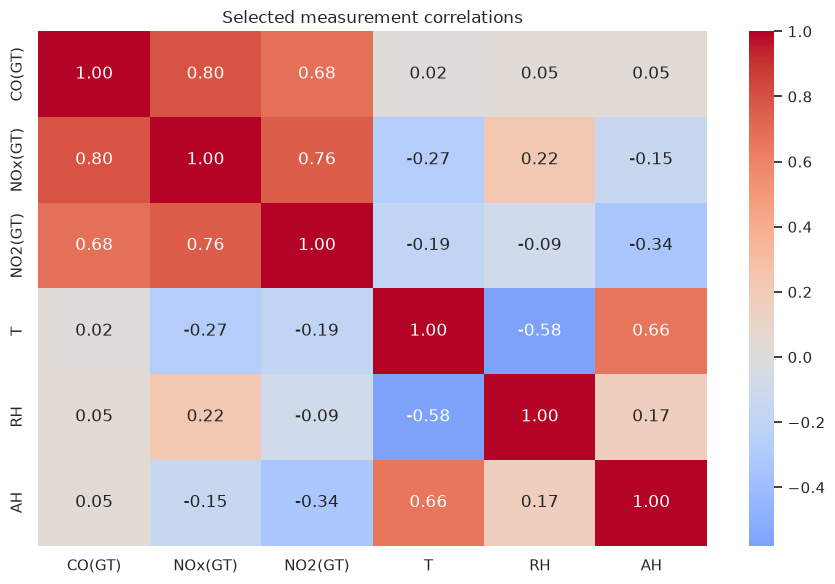

In [11]:
# Relationships
selected = [c for c in ["CO(GT)", "NOx(GT)", "NO2(GT)", "T", "RH", "AH"] if c in df_clean.columns]
if len(selected) > 1:
    plt.figure(figsize=(9, 6))
    sns.heatmap(df_clean[selected].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
    plt.title("Selected measurement correlations")
    plt.tight_layout()
    plt.show()

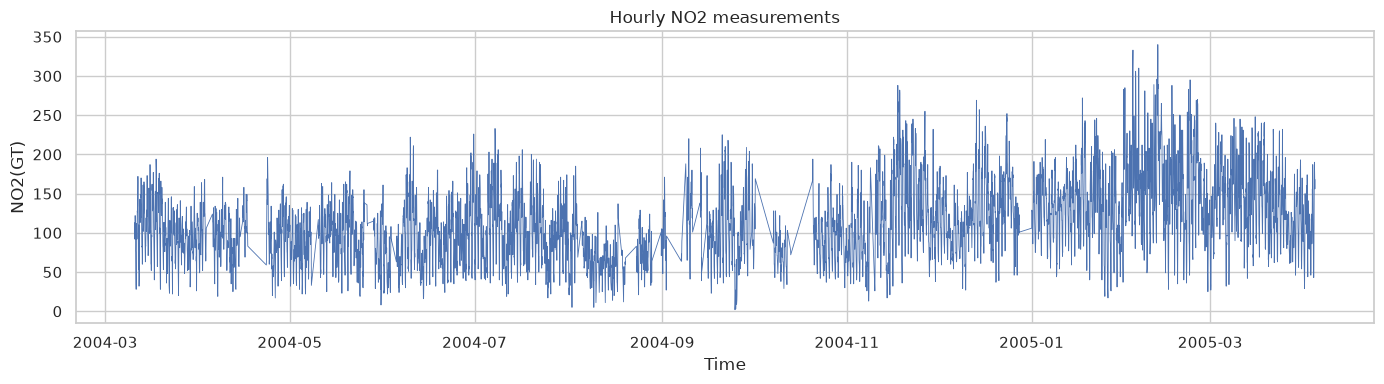

In [12]:
if "Datetime" in df_clean and "NO2(GT)" in df_clean:
    p = df_clean[["Datetime", "NO2(GT)"]].dropna().sort_values("Datetime")
    plt.figure(figsize=(14, 4))
    plt.plot(p.Datetime, p["NO2(GT)"], linewidth=.6)
    plt.xlabel("Time"); plt.ylabel("NO2(GT)")
    plt.title("Hourly NO2 measurements")
    plt.tight_layout(); plt.show()

In [13]:
print("Final rows:", len(df_clean))
print("Final columns:", len(df_clean.columns))

Final rows: 9357
Final columns: 16


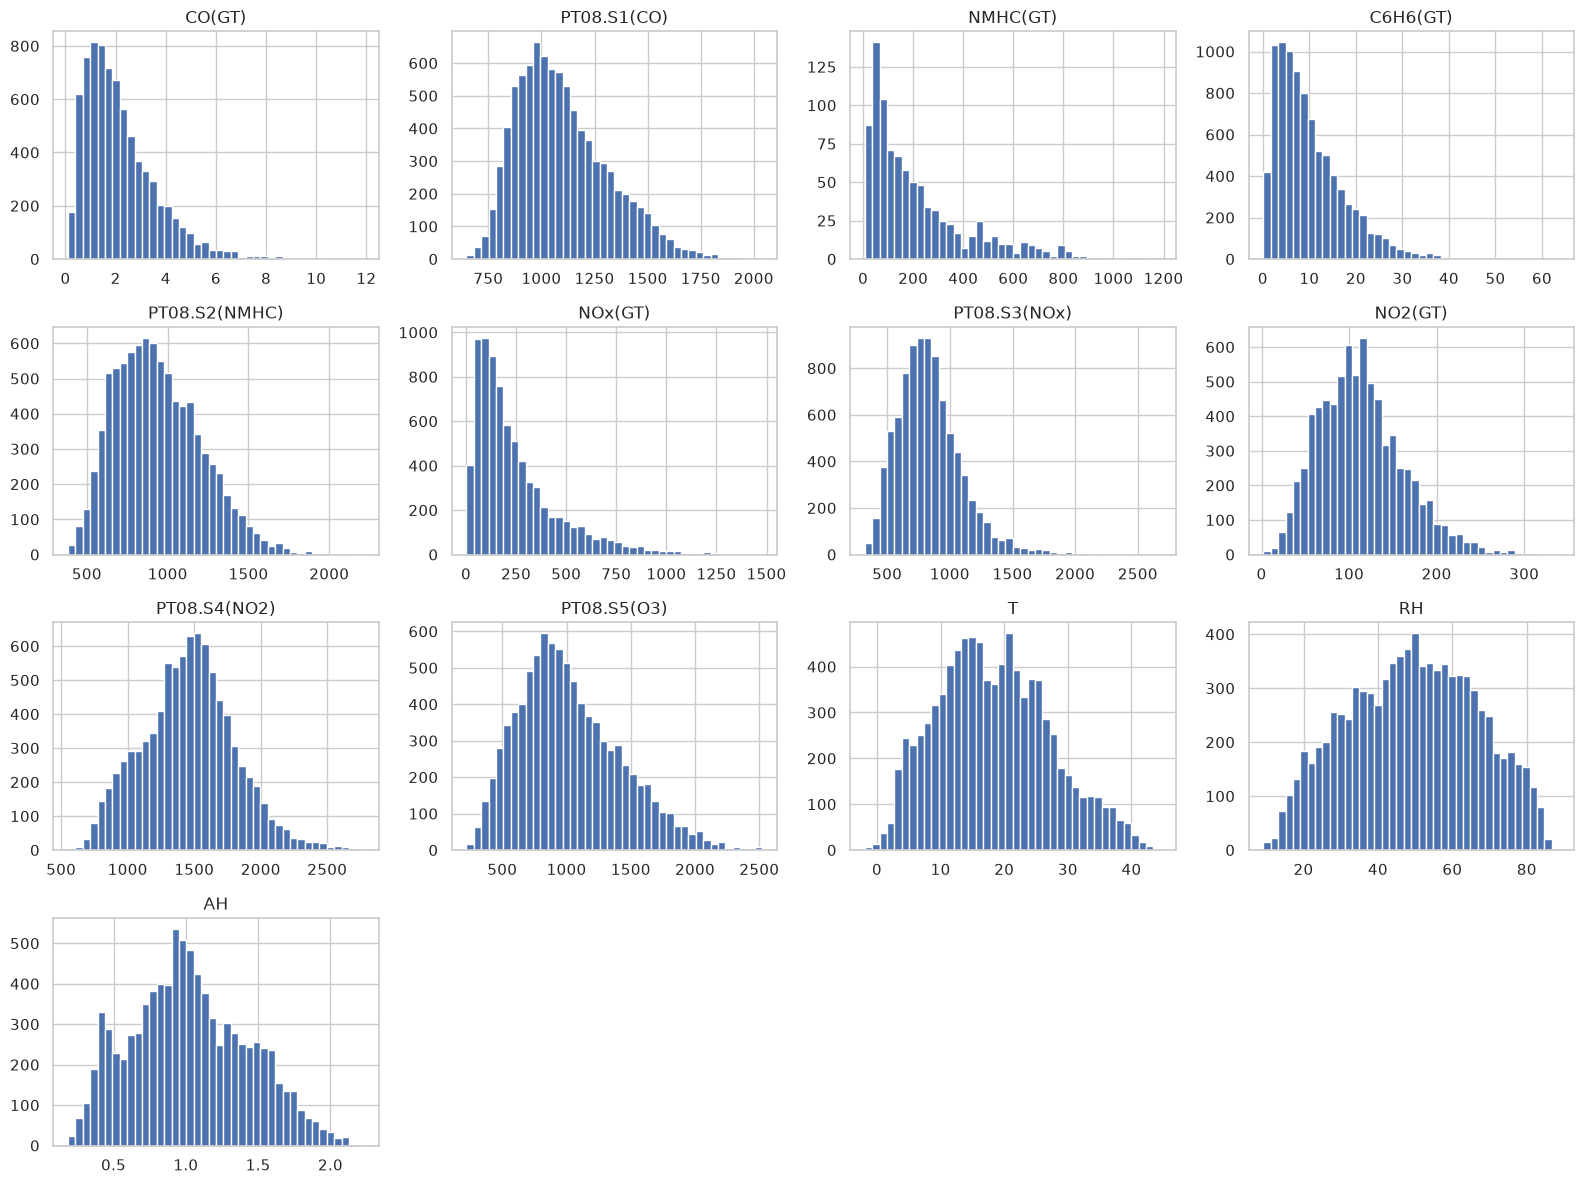

In [14]:
# Measurement Distributions
numeric = df_clean.select_dtypes(include="number")
numeric.hist(figsize=(16, 12), bins=40)
plt.tight_layout()
plt.show()

In [15]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           9357 non-null   str           
 1   Time           9357 non-null   str           
 2   CO(GT)         7674 non-null   float64       
 3   PT08.S1(CO)    8991 non-null   float64       
 4   NMHC(GT)       914 non-null    float64       
 5   C6H6(GT)       8991 non-null   float64       
 6   PT08.S2(NMHC)  8991 non-null   float64       
 7   NOx(GT)        7718 non-null   float64       
 8   PT08.S3(NOx)   8991 non-null   float64       
 9   NO2(GT)        7715 non-null   float64       
 10  PT08.S4(NO2)   8991 non-null   float64       
 11  PT08.S5(O3)    8991 non-null   float64       
 12  T              8991 non-null   float64       
 13  RH             8991 non-null   float64       
 14  AH             8991 non-null   float64       
 15  Datetime       9357 non-null   d

In [16]:
df_clean.describe()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Datetime
count,7674.000000,8991.000000,914.000000,8991.000000,8991.000000,7718.000000,8991.000000,7715.000000,8991.000000,8991.000000,8991.000000,8991.000000,8991.000000,9357
mean,2.152750,1099.833166,218.811816,10.083105,939.153376,246.896735,835.493605,113.091251,1456.264598,1022.906128,18.317829,49.234201,1.025530,2004-09-21 16:00:00
min,0.100000,647.000000,7.000000,0.100000,383.000000,2.000000,322.000000,2.000000,551.000000,221.000000,-1.900000,9.200000,0.184700,2004-03-10 18:00:00
25%,1.100000,937.000000,67.000000,4.400000,734.500000,98.000000,658.000000,78.000000,1227.000000,731.500000,11.800000,35.800000,0.736800,2004-06-16 05:00:00
50%,1.800000,1063.000000,150.000000,8.200000,909.000000,180.000000,806.000000,109.000000,1463.000000,963.000000,17.800000,49.600000,0.995400,2004-09-21 16:00:00
75%,2.900000,1231.000000,297.000000,14.000000,1116.000000,326.000000,969.500000,142.000000,1674.000000,1273.500000,24.400000,62.500000,1.313700,2004-12-28 03:00:00
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000,2005-04-04 14:00:00
std,1.453252,217.080037,204.459921,7.449820,266.831429,212.979168,256.817320,48.370108,346.206794,398.484288,8.832116,17.316892,0.403813,NaN


In [18]:
numeric_cols = df_clean.select_dtypes(include="number").columns

outlier_summary = []

for col in numeric_cols:

    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    outlier_summary.append(
        [col, count]
    )

outliers_df = pd.DataFrame(
    outlier_summary,
    columns=[
        "Feature",
        "Outlier_Count"
    ]
)

outliers_df.sort_values(
    "Outlier_Count",
    ascending=False
)


,Feature,Outlier_Count
5,NOx(GT),435
6,PT08.S3(NOx),241
3,C6H6(GT),228
0,CO(GT),215
1,PT08.S1(CO),118
7,NO2(GT),107
8,PT08.S4(NO2),97
9,PT08.S5(O3),93
4,PT08.S2(NMHC),65
2,NMHC(GT),55


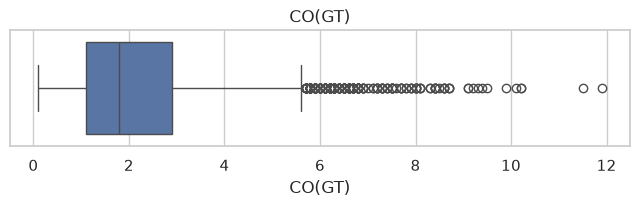

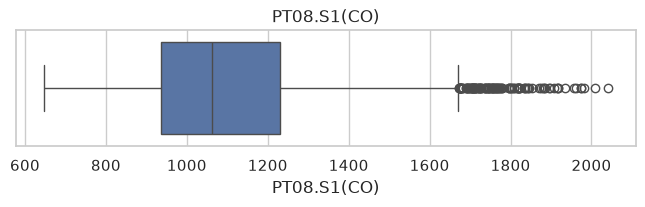

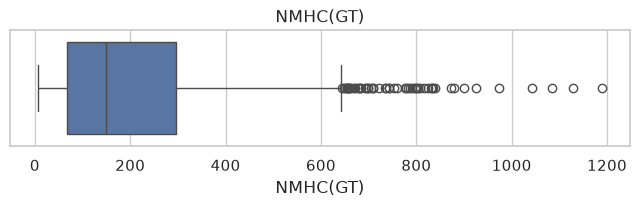

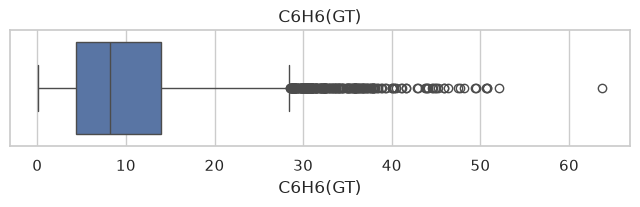

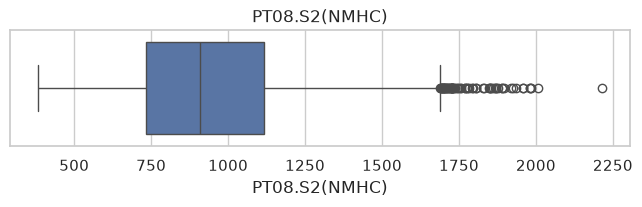

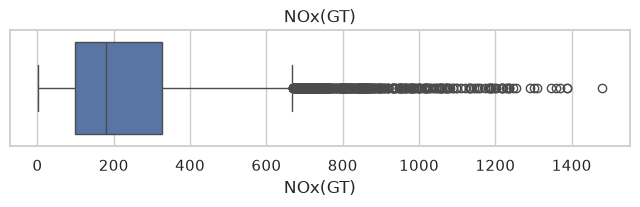

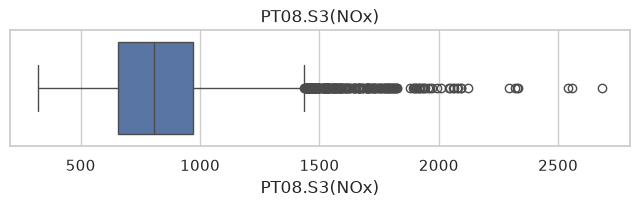

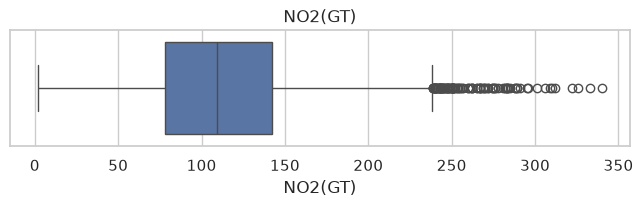

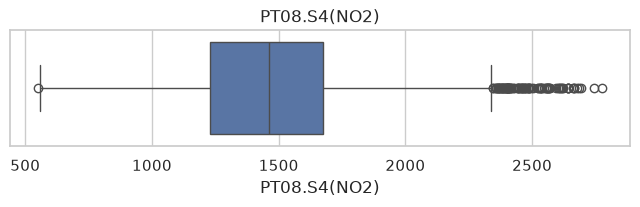

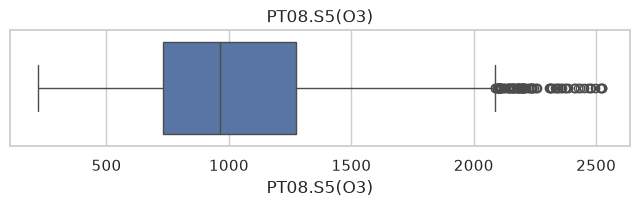

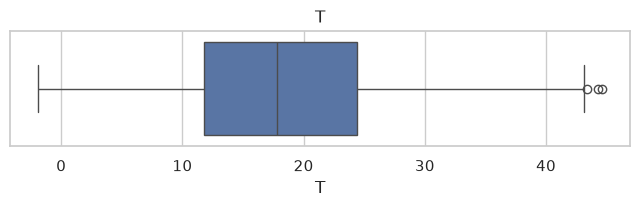

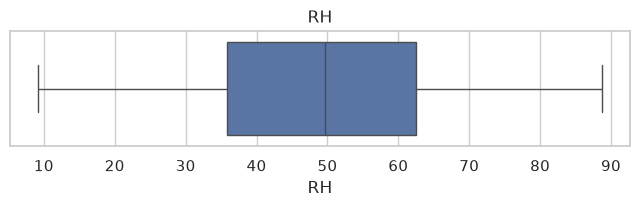

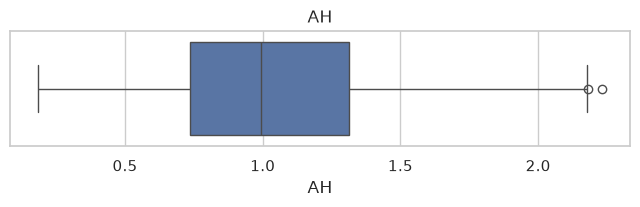

In [19]:
# Outliers
numeric_cols = df_clean.select_dtypes(include="number").columns
for col in numeric_cols:

    plt.figure(figsize=(8, 1.5))

    sns.boxplot(
        x=df_clean[col]
    )

    plt.title(col)
    plt.show()

## 5. Save processed data

In [22]:
print("Raw rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

numeric_cols = df_clean.select_dtypes(include="number").columns

print(
    "Missing numerical measurements:",
    int(df_clean[numeric_cols].isna().sum().sum())
)

Raw rows: 9471
Cleaned rows: 9357
Rows removed: 114
Missing numerical measurements: 16701


In [23]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

cleaned_path = PROCESSED_DIR / "air_quality_cleaned.parquet"

df_clean.to_parquet(cleaned_path, index=False)

print("Cleaned dataset saved:", cleaned_path)

Cleaned dataset saved: /home/chloekc/datahandling/healthyair/data/processed/air_quality_cleaned.parquet


In [24]:
cleaned_path = PROCESSED_DIR / "air_quality_cleaned.parquet"

df_check = pd.read_parquet(cleaned_path)

print("File exists:", cleaned_path.exists())
print("Shape:", df_check.shape)
print("Columns:", df_check.columns.tolist())
print("Datetime range:", df_check["Datetime"].min(), "to", df_check["Datetime"].max())
print("Missing values:", df_check.isna().sum().sum())

File exists: True
Shape: (9357, 16)
Columns: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Datetime']
Datetime range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Missing values: 16701


## Data Cleaning Summary

The raw UCI Air Quality dataset was inspected and prepared for subsequent analysis and forecasting.

The cleaning process:
- Combined the Date and Time columns into a Datetime variable.
- Removed rows with invalid timestamps.
- Sorted observations chronologically.
- Removed completely empty columns.
- Replaced invalid sensor readings coded as -200 with missing values (NaN).
- Examined missingness, measurement distributions, correlations and potential outliers.

Missing measurements were retained rather than imputed during cleaning. Outliers were identified for analysis but were not automatically removed.

The cleaned dataset was saved in Parquet format for use in subsequent data processing and chronological splitting.